# Keysight DSOX1204G – Treiber testen

Test-Notebook direkt neben `keysight_dsox1204g.py`. **Verbindung, Status, Download, Single-Aufnahme
und WaveGen-Konfiguration/Ein-Aus am Gerät erfolgreich geprüft (17.11.2026).** Details: `VALIDIERUNG.md`.
Aufbau: Gen Out direkt auf CH1, Flankentrigger auf CH1, Sollsignal 0–5 V / 20 µs.
Die Pulse kommen vom eingebauten WaveGen; ein separater externer Trigger ist nicht nötig.

Die gespeicherten Ausgaben stammen aus den erfolgreichen Testläufen. Für einen späteren Neustart
stehen die Freigaben in Punkt 0 wieder auf `False`. Die ersten Schritte lesen nur Kennung und Einstellungen.
Kurvendownload/Single sowie WaveGen-Konfiguration/Ausgabe haben getrennte Freigaben.
Kurven bleiben im Kernel-Speicher; dieses Notebook legt keine Messdateien an.

Erster Einstieg: **0 → 1 → 2 → 3 → 4**. Danach **Strg+S**, um die Ausgaben im Notebook zu behalten.
Pro Zelle werden Verbindungen auch bei Fehlern geschlossen. Andere Programme müssen die VISA-Verbindung freigeben.
Nach Änderungen an Python-Dateien den Kernel neu starten. Das Notebook ist für das **DSOX1204G**, nicht das DSOX4054A.

Der vereinheitlichte Verbindungsaufbau und der Konfigurationslader wurden am 18.11.2026 offline geprüft. Die vorhandenen Hardwareausgaben bleiben als bisherige Messnachweise erhalten.


## 0. Umgebung und Konfiguration

Python ≥ 3.10, ein Jupyter-Python-Kernel sowie die Pakete aus `requirements.txt` werden benötigt.
`requirements_plot.txt` enthält zusätzlich Matplotlib. Für die Geräteverbindung ist eine funktionierende
VISA-Installation erforderlich; USBTMC verwendet hier **keinen COM-Port**. Eine bestehende VISA-Installation weiterverwenden.
Die auskommentierten `%pip`-Zeilen installieren bei Bedarf in den aktuell gewählten Kernel.

Kommunikationsparameter und Adresse kommen aus `config/devices.example.json`. Für lokale Einstellungen eine Kopie `devices.local.json` erstellen und `CONFIG_PATH` in der folgenden Zelle anpassen. Die vollständige VISA-Adresse aus Punkt 1 in der gewählten JSON-Datei unter `oscilloscope.resource` eintragen und die Konfigurationszelle erneut ausführen. `communication.visa_backend = ""` verwendet die Standard-VISA-Bibliothek. Der Lader öffnet keine Geräte; `with scope_device` verbindet und schließt pro Testzelle.
Aktueller Testaufbau: **Gen Out → CH1**, Trigger auf CH1, positiver Puls von **0 auf 5 V, 20 µs breit**.
Bei direktem BNC-Kabel CH1 mit Tastkopffaktor 1 und DC-Kopplung verwenden. `HIGHZ` gilt für den
1-MΩ-Eingang ohne externen 50-Ω-Abschluss; die letzte Statusausgabe meldete CH1 mit `IMP ONEM`.
Für beide Flanken samt Low-Pegel davor/danach z. B. 10 µs/div und eine zentrierte Triggerposition wählen.
Trigger: steigende Flanke auf CH1, etwa 2,5 V; vertikal den vollständigen Bereich 0–5 V anzeigen.
Die vorhandenen Geräteeinstellungen werden erst bei den jeweiligen Schreibtests geändert.
Punkt 8/9 verwendet als Test-Wiederholrate 1 Hz; Pulsbreite gilt im Generator-Modus PULSE.
Aufnahmeablauf: **0 → 3 → 7 → 6 → 6b**. Für Punkt 7 darf der manuell eingestellte Generator laufen.
Erneutes Ausführen von Punkt 0 erhält vorhandene Kurven und deren ursprüngliche Metadaten.
Eine neue Ausführung von Punkt 5/7 verwirft die alten Kurven vor dem Aufnahmeversuch; ein Kernel-Neustart leert den Speicher.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import logging
import sys
import time
import unittest
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "LAPIS-Control-Suite"]
project_root = next((p.resolve() for p in candidates
                     if (p / "pyproject.toml").is_file()
                     and (p / "src/lapis_control").is_dir()), None)
if project_root is None:
    raise FileNotFoundError("Open this notebook from the LAPIS project checkout.")
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))
driver_dir = src_dir / "lapis_control/devices/oscilloscope"

# Uncomment once if this kernel lacks the project dependencies:
# %pip install -e "{project_root}[notebook]"

try:
    import numpy as np
    import pyvisa
    from lapis_control.configuration import load_devices
    from lapis_control.devices.oscilloscope.keysight_dsox1204g import KeysightDSOX1204G, ScopeError
except ModuleNotFoundError as exc:
    raise RuntimeError(
        "Treiberabhängigkeiten fehlen im Notebook-Kernel. "
        "Die passende %pip-Zeile oben ausführen und die Zelle erneut starten."
    ) from exc

# Select devices.local.json explicitly when using a local setup.
CONFIG_PATH = project_root / "config/devices.example.json"
scope_device = load_devices(CONFIG_PATH)["oscilloscope"]  # No hardware access.
RESOURCE = scope_device.resource
VISA_BACKEND = scope_device.visa_backend
IO_TIMEOUT_MS = scope_device.timeout_ms
CHANNELS = (1,)  # Gen Out directly connected to CH1; trigger source is also CH1.
WAVEFORM_POINTS = 10000  # Small initial transfer; the returned length is not guaranteed.
WAVEFORM_FORMAT = "WORD"  # WORD, BYTE, or ASCII.
SINGLE_TIMEOUT_S = 30.0
DEBUG = False

ALLOW_ACQUISITION_CHANGES = False  # STOP, transfer settings, and Single acquisition.
ALLOW_WAVEGEN_CONFIG = False
ALLOW_WAVEGEN_OUTPUT = False
CONFIRM_ELECTRICAL_LOOPBACK = False  # WaveGen connected only to the scope, not to the laser.

WAVEGEN_LOAD = "HIGHZ"  # Directly connected to CH1 (1 megohm), without external 50-ohm termination.
WAVEGEN_FREQUENCY_HZ = 1.0  # Test value for sections 8/9, not an application requirement.
WAVEGEN_PULSE_WIDTH_S = 20e-6
WAVEGEN_LOW_V = 0.0
WAVEGEN_HIGH_V = 5.0
WAVEGEN_TEST_SECONDS = 2.0

logging.basicConfig(level=logging.INFO)
logging.getLogger(KeysightDSOX1204G.__module__).setLevel(logging.DEBUG if DEBUG else logging.INFO)
if DEBUG:
    logging.getLogger(KeysightDSOX1204G.__module__).propagate = True

def require_resource():
    if not RESOURCE.strip():
        raise ValueError("Zuerst Punkt 1 ausführen, die VISA-Adresse in CONFIG_PATH eintragen und die Konfiguration erneut starten.")
    return RESOURCE.strip()

def summarize(waves):
    rows = []
    for ch, wave in waves.items():
        finite = wave.voltage_v[np.isfinite(wave.voltage_v)]
        rows.append({
            "channel": ch, "points": wave.raw.size,
            "dt_s": wave.preamble["x_increment"],
            "min_v": float(finite.min()) if finite.size else None,
            "max_v": float(finite.max()) if finite.size else None,
            "missing": int(wave.missing.sum()),
            "clipped_low": int(wave.clipped_low.sum()),
            "clipped_high": int(wave.clipped_high.sum()),
        })
    display(rows)

if "waves" not in globals() or "capture_metadata" not in globals():
    waves = None
    capture_metadata = None
elif waves and capture_metadata:
    print("Letzte Aufnahme bleibt verfügbar:", capture_metadata["resource"],
          "Kanäle:", tuple(waves), "Zeit:", capture_metadata["timestamp_utc"])
print("Python:", sys.executable)
print("Treiberordner:", driver_dir)
print("PyVISA:", pyvisa.__version__, "| NumPy:", np.__version__)


Python: c:\Users\jvelte01\AppData\Local\Python\pythoncore-3.15-64\python.exe
Treiberordner: C:\Users\jvelte01\Desktop\LAPIS-Control Suite\LAPIS-Control-Suite\src\lapis_control\devices\oscilloscope
PyVISA: 1.16.2 | NumPy: 2.5.5


## 1. VISA-Ressourcen auflisten

Öffnet kein Messgerät. Die vollständige Adresse des DSOX1204G in `RESOURCE` übernehmen.
Bei mehreren Geräten nicht allein anhand der USB-Adresse raten: Punkt 2 zeigt die Gerätekennung.
Eine LAN-Adresse kann auch aus Keysight Connection Expert übernommen werden.
Falls schon hier keine VISA-Bibliothek gefunden wird, fehlt die VISA-Laufzeit oder sie passt nicht zum Python-Interpreter.


In [17]:
manager = pyvisa.ResourceManager(VISA_BACKEND)
try:
    print("VISA-Bibliothek:", manager.visalib)
    resources = manager.list_resources()
    for resource in resources:
        print(resource)
    if not resources:
        print("Keine INSTR-Ressourcen gefunden. Anschluss und VISA-Installation prüfen.")
finally:
    manager.close()


VISA-Bibliothek: Visa Library at C:\Windows\system32\visa32.dll
USB0::0x2A8D::0x0396::CN58467706::INSTR
ASRL10::INSTR


## 2. Gerätekennung direkt lesen

Nur `*IDN?`, noch ohne Modellprüfung durch den Treiber. Erwartet wird `DSOX1204G`.
Gerätekennung einschließlich Seriennummer und Firmware für die spätere Fehlersuche speichern.
Es erfolgt kein Reset, kein Aufnahmebeginn und kein Generatorbefehl.


In [16]:
manager = pyvisa.ResourceManager(VISA_BACKEND)
instrument = None
try:
    instrument = manager.open_resource(require_resource())
    instrument.timeout = IO_TIMEOUT_MS
    instrument.write_termination = "\n"
    instrument.read_termination = "\n"
    identification = instrument.query("*IDN?").strip()
    print("Ressource:", RESOURCE)
    print("Gerätekennung:", identification)
finally:
    if instrument is not None:
        instrument.close()
    manager.close()


VisaIOError: VI_ERROR_RSRC_NFOUND (-1073807343): Insufficient location information or the requested device or resource is not present in the system.

## 3. Treiber verbinden und Status lesen

Prüft die Modellkennung und liest Aufnahmezustand, Kanaleinstellungen, Trigger und WaveGen-Einstellungen.
Ein bereits eingeschalteter Generator bleibt bei diesem Lesetest unverändert.
Die Fehlerqueue wird hier nicht ausgelesen, weil deren Abfrage Einträge entfernt.


In [4]:
with scope_device as scope:
    scope_status = scope.status()
    display(scope_status)


{'idn': 'KEYSIGHT TECHNOLOGIES,DSOX1204G,CN58467706,02.00.2018101202',
 'operation': {'register': 0, 'running': False, 'waiting_for_trigger': False},
 'acquisition': 'NORM',
 'sample_rate_hz': 50000000.0,
 'timebase_scale_s': 0.002,
 'timebase_position_s': 0.00802,
 'trigger_setup': ':TRIG:MODE EDGE;SWE NORM;NREJ 0;HFR 0;HOLD +6.00000000E-008;:TRIG:EDGE:SOUR CHAN1;LEV +4.25000E+00;SLOP POS;REJ OFF;COUP DC',
 'channel_setups': {1: ':CHAN1:RANG +20.0E+00;OFFS -2.46875E+00;COUP DC;IMP ONEM;DISP 1;BWL 0;INV 0;UNIT VOLT;PROB +1.0000000E+00;PROB:SKEW +0.0E+00;STYP SING',
  2: ':CHAN2:RANG +16.0E+00;OFFS +3.77400E+00;COUP DC;IMP ONEM;DISP 1;BWL 0;INV 0;UNIT VOLT;PROB +1.0000000E+00;PROB:SKEW +0.0E+00;STYP SING',
  3: ':CHAN3:RANG +3.12E+00;OFFS +0.0E+00;COUP DC;IMP ONEM;DISP 0;BWL 0;INV 0;UNIT VOLT;PROB +1.0000000E+00;PROB:SKEW +0.0E+00;STYP SING',
  4: ':CHAN4:RANG +40.0E+00;OFFS +0.0E+00;COUP DC;IMP ONEM;DISP 1;BWL 0;INV 0;UNIT VOLT;PROB +1.0000000E+00;PROB:SKEW +0.0E+00;STYP SING'},
 'wave

## 4. Wiederholter Lesetest

Zehn Statuszyklen ohne Aufnahme- oder Generatorstart. Bei einem Kommunikationsfehler bricht die Zelle ab;
sie wiederholt den fehlgeschlagenen Befehl nicht automatisch. Mit Kernel-Unterbrechung vorzeitig beenden.


In [5]:
status_samples = []
with scope_device as scope:
    for sample in range(10):
        operation = scope.operation_status()
        generator = scope.wavegen_state()
        status_samples.append({"timestamp_utc": datetime.now(timezone.utc).isoformat(),
                               "operation": operation, "wavegen": generator})
        print(f"{sample + 1}/10: running={operation['running']}, "
              f"waiting_for_trigger={operation['waiting_for_trigger']}, "
              f"WaveGen ON={generator['output']}", flush=True)
        time.sleep(0.5)


1/10: running=False, waiting_for_trigger=False, WaveGen ON=False
2/10: running=False, waiting_for_trigger=False, WaveGen ON=False
3/10: running=False, waiting_for_trigger=False, WaveGen ON=False
4/10: running=False, waiting_for_trigger=False, WaveGen ON=False
5/10: running=False, waiting_for_trigger=False, WaveGen ON=False
6/10: running=False, waiting_for_trigger=False, WaveGen ON=False
7/10: running=False, waiting_for_trigger=False, WaveGen ON=False
8/10: running=False, waiting_for_trigger=False, WaveGen ON=False
9/10: running=False, waiting_for_trigger=False, WaveGen ON=False
10/10: running=False, waiting_for_trigger=False, WaveGen ON=False


## 5. Optional: vorhandene Kurven herunterladen

`ALLOW_ACQUISITION_CHANGES = True` setzen und die Konfiguration erneut ausführen.
Der Download **stoppt die Aufnahme** und ändert die Waveform-Übertragungseinstellungen; er startet keine neue Aufnahme.
Die gewählten Kanäle müssen bereits vor der Aufnahme eingeblendet gewesen sein.
MAIN/RTIME und NORMAL/HRESOLUTION/AVERAGE werden unterstützt, Peak-Detect und Segmente nicht.
Eine Übertragungsanforderung von 10.000 Punkten garantiert keine entsprechende Rückgabelänge.
Das Scope bleibt anschließend gestoppt; es wird nicht automatisch auf RUN zurückgeschaltet.


In [6]:
waves = None
capture_metadata = None
if ALLOW_ACQUISITION_CHANGES:
    with scope_device as scope:
        settings_before = scope.status()
        downloaded = scope.read_waveforms(CHANNELS, points=WAVEFORM_POINTS,
                                          format=WAVEFORM_FORMAT)
        metadata = {"resource": RESOURCE, "idn": scope.idn,
                    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                    "source": "existing_record", "settings_before": settings_before,
                    "settings_after_download": scope.status()}
    waves, capture_metadata = downloaded, metadata
    summarize(waves)
else:
    print("Übersprungen: ALLOW_ACQUISITION_CHANGES ist False.")


[{'channel': 1,
  'points': 10000,
  'dt_s': 2e-06,
  'min_v': -0.2576949472000001,
  'max_v': 4.8679326752,
  'missing': 0,
  'clipped_low': 0,
  'clipped_high': 0}]

## 6. Kurven anzeigen

Plottet nur bereits heruntergeladene Daten, kein Gerätezugriff. Zeit in µs relativ zur Gerätezeitreferenz,
Spannung in V gemäß Tastkopffaktor/Preamble. Die Zeitachse ist noch keine physikalisch kalibrierte TOF-Achse.
Für flüssige Darstellung werden höchstens ungefähr 20.000 Punkte je Kurve gezeichnet;
in `waves` bleiben sämtliche Punkte erhalten. Clipping und fehlende Werte stehen in der Zusammenfassung.
Für den Plot muss Matplotlib installiert sein.


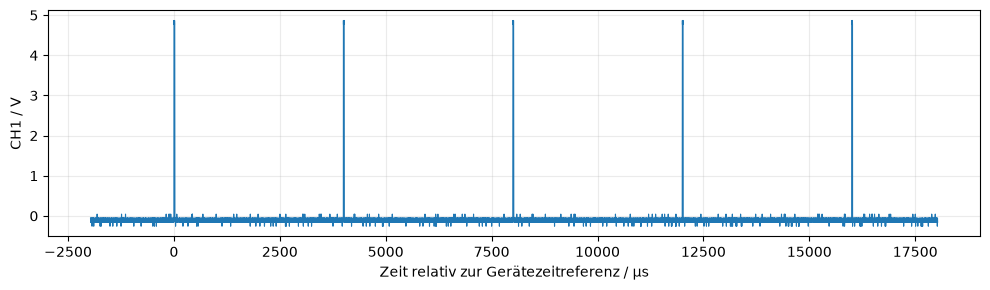

In [7]:
def plot_waves(data):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(len(data), 1, sharex=True, squeeze=False,
                             figsize=(10, 3 * len(data)))
    for ax, (ch, wave) in zip(axes.flat, data.items()):
        stride = max(1, int(np.ceil(wave.raw.size / 20000)))
        ax.plot(wave.time_s[::stride] * 1e6, wave.voltage_v[::stride], linewidth=0.8)
        ax.set_ylabel(f"CH{ch} / V")
        ax.grid(alpha=0.25)
    axes[-1, 0].set_xlabel("Zeit relativ zur Gerätezeitreferenz / µs")
    fig.tight_layout()
    plt.show()

if waves:
    plot_waves(waves)
else:
    print("Keine Kurven verfügbar. Zuerst Punkt 5 oder 7 erfolgreich ausführen.")


## 6b. TTL-Pegel und Pulsbreite aus CH1 bestimmen

Nur Auswertung der zuletzt heruntergeladenen Kurve, kein Gerätezugriff. Nach Punkt 7 zuerst Punkt 6
für den Plot und dann diese Zelle ausführen. Erwartet werden 0 V / 5 V und 20 µs.
Die Breite wird zwischen steigender und fallender Flanke bei der festen Schwelle 2,5 V berechnet;
zwischen benachbarten Samples wird linear interpoliert. Pegel sind Mediane unter/über dieser Schwelle.
Nur vollständige Pulse mit Low-Pegel an beiden Fensterrändern und ohne fehlende/geclippte Werte
werden ausgewertet. Bei Problemen Zeitfenster, Vertikalskala, Tastkopffaktor und Trigger prüfen.
Das ist eine Kurvenauswertung ohne festgelegte Bestehensgrenzen; Werte mit der Scope-Anzeige vergleichen.
Die Wiederholrate lässt sich nur mit mindestens zwei vollständigen Pulsen im selben Fenster schätzen.


In [8]:
def analyze_ttl(wave, *, low_v=0.0, high_v=5.0, width_s=20e-6):
    t, v = wave.time_s, wave.voltage_v
    if (len(t) < 5 or not np.all(np.isfinite(t)) or not np.all(np.isfinite(v))
            or not np.all(np.diff(t) > 0)
            or np.any(wave.missing | wave.clipped_low | wave.clipped_high)):
        raise ValueError("Zu wenige, fehlende, geclippte oder ungültige Messpunkte.")
    threshold = (low_v + high_v) / 2
    above = v >= threshold
    if above[0] or above[-1]:
        raise ValueError("Puls am Fensterrand: vor und nach dem Puls muss Low sichtbar sein.")
    rising = np.flatnonzero(~above[:-1] & above[1:])
    falling = np.flatnonzero(above[:-1] & ~above[1:])
    if not len(rising) or len(rising) != len(falling) or np.any(falling <= rising):
        raise ValueError("Kein vollständiger positiver Puls bei der Soll-Mittenspannung gefunden.")
    if above.sum() < 3 or (~above).sum() < 3:
        raise ValueError("Zu wenige Samples auf dem High- oder Low-Pegel.")

    def crossing(indices):
        fraction = (threshold - v[indices]) / (v[indices + 1] - v[indices])
        return t[indices] + fraction * (t[indices + 1] - t[indices])

    rise_s, fall_s = crossing(rising), crossing(falling)
    widths = fall_s - rise_s
    low, high = float(np.median(v[~above])), float(np.median(v[above]))
    width = float(np.median(widths))
    return {
        "channel": wave.channel, "complete_pulses": len(widths),
        "sample_interval_ns": float(np.median(np.diff(t)) * 1e9),
        "low_median_v": low, "low_deviation_v": low - low_v,
        "high_median_v": high, "high_deviation_v": high - high_v,
        "threshold_v": threshold, "width_median_us": width * 1e6,
        "width_deviation_us": (width - width_s) * 1e6,
        "widths_us_first_10": (widths[:10] * 1e6).tolist(),
        "frequency_hz": float(1 / np.median(np.diff(rise_s))) if len(rise_s) > 1 else None,
    }

ttl_result = None
if waves and 1 in waves:
    try:
        ttl_result = analyze_ttl(waves[1], low_v=WAVEGEN_LOW_V,
                                 high_v=WAVEGEN_HIGH_V, width_s=WAVEGEN_PULSE_WIDTH_S)
        display(ttl_result)
        if ttl_result["frequency_hz"] is None:
            print("Nur ein vollständiger Puls: Wiederholrate ist aus dieser Kurve nicht bestimmbar.")
    except ValueError as exc:
        print("Keine belastbare TTL-Auswertung:", exc)
else:
    print("Zuerst mit CHANNELS = (1,) eine CH1-Kurve über Punkt 5 oder 7 herunterladen.")


{'channel': 1,
 'complete_pulses': 5,
 'sample_interval_ns': 2000.0000000002653,
 'low_median_v': -0.15719244480000016,
 'low_deviation_v': -0.15719244480000016,
 'high_median_v': 4.8679326752,
 'high_deviation_v': -0.13206732480000039,
 'threshold_v': 2.5,
 'width_median_us': 19.8825251020978,
 'width_deviation_us': -0.11747489790220109,
 'widths_us_first_10': [19.90170956851193,
  19.923341428631712,
  19.8608932419804,
  19.8825251020978,
  19.86410801434191],
 'frequency_hz': 250.0}

## 7. Optional: neue Einzelaufnahme mit WaveGen-Signal auf CH1

Benötigt `ALLOW_ACQUISITION_CHANGES = True`. Zuerst Signale, Triggerquelle, Triggerpegel,
Tastkopffaktoren und Skalen am Scope passend einstellen. Die Zelle aktiviert die ausgewählten Kanäle,
setzt MAIN/RTIME/NORMAL und Trigger-Sweep NORMAL, stellt Single scharf und wartet bis zu 30 Sekunden.
Für den aktuellen Aufbau: Gen Out liefert die 20-µs-Pulse an CH1, der Flankentrigger überwacht CH1.
Ein separater externer Trigger ist dafür nicht erforderlich.
Läuft der Generator bereits, erfolgt die Aufnahme bei einer seiner nächsten steigenden Flanken.
Ist er aus, nach der Bereitschaftsmeldung den bereits eingestellten Generator am Frontpanel einschalten.
Diese Zelle lässt den manuell geschalteten Generator unverändert; bei Bedarf danach am Gerät ausschalten.
Ohne frischen Trigger wird keine alte Aufnahme als neue Messung zurückgegeben.

**Single bezeichnet eine Oszilloskop-Aufnahme. Diese Zelle löst keinen Laser und keinen WaveGen aus.**
Bei Erfolg anschließend Punkt 6 und 6b für Plot und TTL-Auswertung ausführen. Bei einem Fehler bleiben `waves` und Metadaten leer.


In [9]:
waves = None
capture_metadata = None
if ALLOW_ACQUISITION_CHANGES:
    with scope_device as scope:
        settings_before = scope.status()
        try:
            scope.write_scpi(":TIMebase:MODE MAIN")
            scope.configure_acquisition("NORMAL")
            for ch in CHANNELS:
                scope.configure_channel(ch, enabled=True)
            scope.arm_single()
            scope.wait_until_armed()
            print("Bereit: warte auf die steigende Flanke des WaveGen-Signals an CH1. "
                  "WaveGen wird nicht eingeschaltet.", flush=True)
            scope.wait_for_single(timeout_s=SINGLE_TIMEOUT_S)
            downloaded = scope.read_waveforms(CHANNELS, points=WAVEFORM_POINTS,
                                              format=WAVEFORM_FORMAT, stop=False)
            metadata = {"resource": RESOURCE, "idn": scope.idn,
                        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                        "source": "fresh_single", "settings_before": settings_before,
                        "settings_after_download": scope.status()}
        except BaseException:
            # Attempt STOP without hiding the original error.
            try:
                scope.stop()
            except Exception:
                logging.exception("Aufnahme nach Abbruch nicht bestätigt gestoppt")
            raise
    waves, capture_metadata = downloaded, metadata
    summarize(waves)
else:
    print("Übersprungen: ALLOW_ACQUISITION_CHANGES ist False.")


Bereit: warte auf die steigende Flanke des WaveGen-Signals an CH1. WaveGen wird nicht eingeschaltet.


[{'channel': 1,
  'points': 10000,
  'dt_s': 2e-06,
  'min_v': -0.2576949472000001,
  'max_v': 4.9684351776,
  'missing': 0,
  'clipped_low': 0,
  'clipped_high': 0}]

## 8. Optional: WaveGen konfigurieren, Ausgang AUS

Benötigt `ALLOW_WAVEGEN_CONFIG = True` und eine bestätigte `WAVEGEN_LOAD` (`HIGHZ` oder `50OHM`).
Die Lastangabe beschreibt die angeschlossene Last; eine falsche Angabe verfälscht die tatsächlichen Pegel.
Ein bereits laufender Generator wird hier nicht übernommen: zuerst bewusst am Gerät ausschalten.
Die Zelle konfiguriert eine periodische Pulsfolge mit **0–5 V, 20 µs und 1 Hz** gemäß Punkt 0,
liest Parameter zurück und lässt den Ausgang ausgeschaltet. `HIGHZ` gilt hier für den direkten CH1-Anschluss.
Es werden keine Pulse ausgegeben. Zurückgelesene Pegel sind keine Messung der realen Ausgangsspannung.


In [20]:
def configure_test_wavegen(scope):
    if WAVEGEN_LOAD not in ("HIGHZ", "50OHM"):
        raise ValueError("Zuerst die reale Last prüfen und WAVEGEN_LOAD festlegen.")
    if scope.wavegen_state()["output"]:
        raise ScopeError("WaveGen läuft bereits; zuerst bewusst am Gerät ausschalten.")
    return scope.configure_ttl(load=WAVEGEN_LOAD, frequency_hz=WAVEGEN_FREQUENCY_HZ,
                               pulse_width_s=WAVEGEN_PULSE_WIDTH_S,
                               low_v=WAVEGEN_LOW_V, high_v=WAVEGEN_HIGH_V)

if ALLOW_WAVEGEN_CONFIG:
    with scope_device as scope:
        display(configure_test_wavegen(scope))
else:
    print("Übersprungen: ALLOW_WAVEGEN_CONFIG ist False.")


{'output': False,
 'function': 'PULS',
 'load': 'ONEM',
 'polarity': 'NORM',
 'modulation': False,
 'noise_percent': 0.0,
 'frequency_hz': 1.0,
 'pulse_width_s': 2e-05,
 'low_v': 0.0,
 'high_v': 5.0}

## 9. Optional: elektrischer WaveGen-Test am Oszilloskop

Erst nach erfolgreichem Scope-Lesetest verwenden. WaveGen nur mit einem geeigneten Scope-Eingang verbinden,
die Laseransteuerung dafür trennen. Am Scope die realen Pegel, Pulsbreite und Wiederholrate überprüfen.
Benötigt **alle drei** Freigaben: `ALLOW_WAVEGEN_CONFIG`, `ALLOW_WAVEGEN_OUTPUT` und
`CONFIRM_ELECTRICAL_LOOPBACK`, außerdem die bestätigte Lastangabe.

Die Zelle konfiguriert erneut, weil sie eine eigene Verbindung öffnet, und startet für zwei Sekunden
eine **periodische Pulsfolge**, keinen garantierten Einzelpuls. Danach und bei Python-Ausnahmen wird OFF versucht.
Bei Kabelverlust oder hartem Prozessabbruch kann die Abschaltung nicht garantiert werden.
Das Scope wird hier nicht automatisch scharfgestellt. Nach Punkt 5/7 steht es auf STOP: vor diesem Test
am Frontpanel **Single** mit Trigger auf CH1 scharfstellen. Nach Punkt 9 über **5 → 6 → 6b** herunterladen
und prüfen. Für einen separaten Test des Single-Ablaufs per Treiber Punkt 7 mit laufendem Generator verwenden.


In [18]:
if ALLOW_WAVEGEN_CONFIG and ALLOW_WAVEGEN_OUTPUT and CONFIRM_ELECTRICAL_LOOPBACK:
    if isinstance(WAVEGEN_TEST_SECONDS, bool) or not np.isfinite(WAVEGEN_TEST_SECONDS) or not 0 < WAVEGEN_TEST_SECONDS <= 5:
        raise ValueError("Für den ersten Test eine Dauer zwischen 0 und 5 Sekunden wählen.")
    with scope_device as scope:
        configure_test_wavegen(scope)
        try:
            scope.wavegen_output(True)
            print("Periodische Pulsfolge aktiv; Signal am Scope beobachten.", flush=True)
            time.sleep(WAVEGEN_TEST_SECONDS)
        finally:
            scope.wavegen_output(False)
        display(scope.wavegen_state())
else:
    print("Übersprungen: WaveGen-Konfiguration, Ausgabe und elektrischer Testaufbau müssen freigegeben sein.")


Periodische Pulsfolge aktiv; Signal am Scope beobachten.


{'output': False,
 'function': 'PULS',
 'load': 'ONEM',
 'polarity': 'NORM',
 'modulation': False,
 'noise_percent': 0.0,
 'frequency_hz': 1.0,
 'pulse_width_s': 2e-05,
 'low_v': 0.0,
 'high_v': 5.0}

## 10. Offline-Regressionstests

Verwendet die vorhandenen Tests aus `tests/test_driver.py` mit simulierten VISA-Geräten.
Kein echtes Messgerät wird geöffnet, kein Generator gestartet. NumPy und PyVISA müssen installiert sein.
Die Simulation ersetzt weder den USB/VISA-Test noch den Vergleich von Kurven und Ausgangspegeln am Gerät.


In [19]:
from lapis_control.devices.oscilloscope.tests import test_driver

suite = unittest.defaultTestLoader.loadTestsFromModule(test_driver)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful(), "Mindestens ein Offline-Test ist fehlgeschlagen."


test_ascii_not_scaled_twice (test_driver.DriverTests.test_ascii_not_scaled_twice) ... ok
test_average_uses_measurement_record (test_driver.DriverTests.test_average_uses_measurement_record) ... WARNING:keysight_dsox1204g:CH1 enthält am Anzeigebereich abgeschnittene Werte.
ok
test_binary_timeout_restores_termination_locks_io (test_driver.DriverTests.test_binary_timeout_restores_termination_locks_io) ... ok
test_byte_scale (test_driver.DriverTests.test_byte_scale) ... ok
test_capture_script_waits_and_does_not_fire_generator (test_driver.DriverTests.test_capture_script_waits_and_does_not_fire_generator) ... WARNING:keysight_dsox1204g:CH1 enthält am Anzeigebereich abgeschnittene Werte.
ok
test_changed_frequency_blocks_enable (test_driver.DriverTests.test_changed_frequency_blocks_enable) ... ok
test_clamped_voltage_blocks_enable (test_driver.DriverTests.test_clamped_voltage_blocks_enable) ... ok
test_close_off_after_transport_error (test_driver.DriverTests.test_close_off_after_transport_erro

## Bei Fehlern

Ausgabe speichern und den ersten Traceback prüfen. Für SCPI-Befehle und Antworten `DEBUG = True`
setzen und die Konfigurationszelle erneut ausführen. Bei I/O-Fehlern schließt die jeweilige Zelle ihre Verbindung;
der fehlgeschlagene Befehl wird nicht automatisch wiederholt. Nicht sofort mit WaveGen-Tests fortfahren.
Kein automatischer Reset und kein automatisches `recover()`, da diese den Gerätezustand verändern würden.

Der Standard-Lesetest bewahrt die Fehlerqueue. `read_errors()` liest und **entfernt** gespeicherte Fehlereinträge;
diese Abfrage nur bewusst zur Diagnose verwenden. Nach Kurvendownload/Single bleibt das Scope gestoppt.
Bei Bedarf RUN am Frontpanel wieder aktivieren. Gerätezustand und letzte Ausgaben sind keine Abschaltgarantie für externe Geräte.
